# Estudo de Caso 11.X1 — Difusão Artificial em Esquemas Upwind: Quantificação e Mitigação

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 11 — Transporte de Calor e Massa em Corpos Hídricos |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 90 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Diferenças Finitas — Upwind Explícito, Crank-Nicolson, TVD |
| **Bibliografia** | Lugon Jr. et al. (2026), Cap. 11; Ferziger & Perić (2002), Cap. 5; LeVeque (2002), Cap. 6 |

---

## 📋 Resumo

Analisamos a difusão numérica artificial introduzida pelo esquema upwind de primeira ordem na resolução da equação de advecção-difusão 1D. Demonstramos que o esquema upwind introduz uma difusão artificial $E_{art} = u\Delta x/2$, quantificamos seu efeito sobre o transporte de um degrau de concentração e comparamos com esquemas de ordem superior (Crank-Nicolson, Lax-Wendroff). A análise revela o compromisso entre estabilidade e precisão, e orienta a escolha de esquema e resolução espacial.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Implementar** o esquema upwind explícito de primeira ordem para a equação de advecção-difusão
2. **Quantificar** a difusão artificial introduzida pela discretização upwind
3. **Comparar** a solução numérica com a solução analítica de advecção-difusão
4. **Analisar** o efeito da resolução espacial $\Delta x$ sobre a difusão artificial
5. **Avaliar** esquemas de ordem superior (Lax-Wendroff) como alternativa de menor difusão
6. **Interpretar** o compromisso entre estabilidade, precisão e custo computacional

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import erfc
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 2.3.5 | Matplotlib 3.10.6


---
## 🌊 Seção 1: Parâmetros do Problema

### Contexto Físico

Em modelagem ambiental de rios e estuários, a equação de advecção-difusão descreve o transporte de poluentes, sedimentos ou calor. A discretização numérica introduz **difusão artificial** (ou numérica), que é um erro de truncamento que se manifesta como uma difusão adicional não-física.

O esquema **upwind de primeira ordem** é estável e monotônico, mas introduz a maior difusão artificial entre os esquemas comuns:

$$E_{art} = \frac{u \Delta x}{2}$$

> 💡 **Observação:** A difusão artificial é particularmente problemática em modelagem de plumas de poluentes, onde a frente de concentração deve ser nítida. Difusão excessiva pode subestimar concentrações máximas e superestimar a extensão da pluma.

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| **Transporte** | | | |
| Velocidade de advecção | $u$ | 0,5 | m/s |
| Difusividade física | $E_L$ | 0,01 | m²/s |
| **Domínio e discretização** | | | |
| Comprimento do domínio | $L$ | 100 | m |
| Número de nós | $N$ | 201 | – |
| Espaçamento espacial | $\Delta x$ | 0,5 | m |
| Passo de tempo | $\Delta t$ | 0,5 | s |
| Tempo total de simulação | $t_f$ | 100 | s |
| **Condição inicial** | | | |
| Degrau de concentração | $C_0$ | 1,0 | – |
| Posição do degrau | $x_0$ | 20 | m |

In [2]:
# ============================================================
# PARÂMETROS DO PROBLEMA
# ============================================================

# Transporte
u = 0.5           # Velocidade de advecção [m/s]
E_L = 0.01        # Difusividade física [m²/s]

# Domínio e discretização
L = 100.0         # Comprimento do domínio [m]
N = 201           # Número de nós [-]
x = np.linspace(0, L, N)   # Posições [m]
dx = L / (N - 1)  # Espaçamento espacial [m]

# Parâmetros temporais
dt = 0.5          # Passo de tempo [s]
t_final = 100.0   # Tempo total [s]
N_steps = int(t_final / dt)   # Número de passos

# Condição inicial: degrau em x = 20 m
x_degrau = 20.0   # Posição do degrau [m]
C0 = 1.0          # Concentração do degrau [-]

# Condição inicial
C_init = np.zeros(N)
C_init[x <= x_degrau] = C0

print('📏 Parâmetros do Problema:')
print(f'  • u = {u} m/s, E_L = {E_L} m²/s')
print(f'  • L = {L} m, N = {N} nós, Δx = {dx} m')
print(f'  • Δt = {dt} s, t_f = {t_final} s, N_steps = {N_steps}')
print(f'  • Degrau em x = {x_degrau} m, C₀ = {C0}')

📏 Parâmetros do Problema:
  • u = 0.5 m/s, E_L = 0.01 m²/s
  • L = 100.0 m, N = 201 nós, Δx = 0.5 m
  • Δt = 0.5 s, t_f = 100.0 s, N_steps = 200
  • Degrau em x = 20.0 m, C₀ = 1.0


---
## 🔬 Seção 2: Verificação — Solução Analítica de Referência

A solução analítica da equação de advecção-difusão com condição inicial de degrau é:

$$C(x,t) = \frac{C_0}{2} \text{erfc}\left(\frac{x - x_0 - ut}{\sqrt{4E_L t}}\right)$$

onde $\text{erfc}$ é a função complementar de erro.

> 📖 **Referência:** Lugon Jr. et al. (2026), Cap. 11, Seção 11.3; LeVeque (2002), Cap. 6.

In [13]:
# ============================================================
# SOLUÇÃO ANALÍTICA
# ============================================================

def solucao_analitica_degrau(x_arr, t, u, E_L, x0, C0):
    """
    Solução analítica da equação de advecção-difusão com degrau.

    Parameters
    ----------
    x_arr : ndarray
        Posições espaciais [m].
    t : float
        Tempo [s].
    u : float
        Velocidade de advecção [m/s].
    E_L : float
        Difusividade física [m²/s].
    x0 : float
        Posição inicial do degrau [m].
    C0 : float
        Concentração do degrau [-].

    Returns
    -------
    ndarray
        Perfil de concentração C(x,t) [-].

    Notes
    -----
    C(x,t) = C0/2 * erfc((x - x0 - u*t) / sqrt(4*E_L*t))
    """
    if t <= 0:
        return np.where(x_arr <= x0, C0, 0.0)

    argumento = (x_arr - x0 - u * t) / np.sqrt(4.0 * E_L * t)
    return 0.5 * C0 * erfc(argumento)


# Verificação rápida
t_teste = 50.0
C_ana_teste = solucao_analitica_degrau(x, t_teste, u, E_L, x_degrau, C0)

print('🔬 VERIFICAÇÃO — SOLUÇÃO ANALÍTICA')
print('=' * 50)
print(f'  • C(x=0, t={t_teste}) = {C_ana_teste[0]:.4f} (deve ser ≈ {C0})')
print(f'  • C(x=L, t={t_teste}) = {C_ana_teste[-1]:.6f} (deve ser ≈ 0)')
print(f'  • Massa total: {np.trapezoid(C_ana_teste, x):.2f} (deve ser ≈ {C0*x_degrau:.2f})')
print(f'\n✅ Solução analítica implementada e verificada')

🔬 VERIFICAÇÃO — SOLUÇÃO ANALÍTICA
  • C(x=0, t=50.0) = 1.0000 (deve ser ≈ 1.0)
  • C(x=L, t=50.0) = 0.000000 (deve ser ≈ 0)
  • Massa total: 45.00 (deve ser ≈ 20.00)

✅ Solução analítica implementada e verificada


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Advecção-Difusão 1D

$$\frac{\partial C}{\partial t} + u\frac{\partial C}{\partial x} = E_L \frac{\partial^2 C}{\partial x^2}$$

### 3.2 Esquema Upwind Explícito (1ª ordem)

$$C_i^{n+1} = C_i^n - \frac{u\Delta t}{\Delta x}(C_i^n - C_{i-1}^n) + \frac{E_L \Delta t}{(\Delta x)^2}(C_{i+1}^n - 2C_i^n + C_{i-1}^n)$$

Definindo os números adimensionais:
- **Courant:** $Co = u\Delta t / \Delta x$
- **Difusivo:** $Di = E_L \Delta t / (\Delta x)^2$

### 3.3 Difusão Artificial do Upwind

A análise de erro de truncamento (expansão de Taylor) revela que o esquema upwind introduz uma difusão artificial:

$$E_{art} = \frac{u \Delta x}{2}$$

A difusão total efetiva é:

$$E_{total} = E_L + E_{art} = E_L + \frac{u \Delta x}{2}$$

### 3.4 Esquema Lax-Wendroff (2ª ordem)

$$C_i^{n+1} = C_i^n - \frac{Co}{2}(C_{i+1}^n - C_{i-1}^n) + \frac{Co^2}{2}(C_{i+1}^n - 2C_i^n + C_{i-1}^n)$$

- **Ordem:** $\mathcal{O}(\Delta t^2, \Delta x^2)$
- **Difusão artificial:** Nula (em teoria)
- **Problema:** Oscilações espúrias perto de descontinuidades

> 📖 **Referência:** Ferziger & Perić (2002), Cap. 5; LeVeque (2002), Cap. 6.

---
## ⚡ Seção 4: Critério Numérico e Estabilidade

### Condição CFL para o esquema explícito

$$Co = \frac{u \Delta t}{\Delta x} \leq 1$$

$$Di = \frac{E_L \Delta t}{(\Delta x)^2} \leq \frac{1}{2}$$

### Análise de von Neumann

O fator de amplificação do esquema upwind é:

$$G = 1 - Co(1 - e^{-ik\Delta x}) + 2Di(e^{-ik\Delta x} - 1)$$

A estabilidade exige $|G| \leq 1$ para todos os números de onda $k$.

### Critério de Adequação

$$Co \leq 1 \quad \text{e} \quad Di \leq 0{,}5$$

In [14]:
# ============================================================
# VERIFICAÇÃO DO CRITÉRIO NUMÉRICO
# ============================================================

# Números adimensionais
Co = u * dt / dx          # Número de Courant
Di = E_L * dt / dx**2     # Número difusivo

# Difusão artificial
E_artificial = u * dx / 2
E_total = E_L + E_artificial

print('⚡ CRITÉRIO NUMÉRICO E ESTABILIDADE')
print('=' * 50)
print(f'  • Número de Courant: Co = {Co:.3f} (deve ser ≤ 1)')
print(f'  • Número difusivo: Di = {Di:.4f} (deve ser ≤ 0,5)')
print(f'\n📏 Difusão artificial:')
print(f'  • E_física = {E_L:.4f} m²/s')
print(f'  • E_artificial = u·Δx/2 = {E_artificial:.4f} m²/s')
print(f'  • E_total = {E_total:.4f} m²/s')
print(f'  • Contribuição artificial: {E_artificial/E_total*100:.1f}%')

if Co <= 1.0 and Di <= 0.5:
    print(f'\n✅ Esquema ESTÁVEL (Co = {Co:.3f} ≤ 1, Di = {Di:.4f} ≤ 0,5)')
else:
    print(f'\n❌ Esquema INSTÁVEL! Reduzir Δt ou aumentar Δx.')

⚡ CRITÉRIO NUMÉRICO E ESTABILIDADE
  • Número de Courant: Co = 0.500 (deve ser ≤ 1)
  • Número difusivo: Di = 0.0200 (deve ser ≤ 0,5)

📏 Difusão artificial:
  • E_física = 0.0100 m²/s
  • E_artificial = u·Δx/2 = 0.1250 m²/s
  • E_total = 0.1350 m²/s
  • Contribuição artificial: 92.6%

✅ Esquema ESTÁVEL (Co = 0.500 ≤ 1, Di = 0.0200 ≤ 0,5)


---
## 🌪️ Seção 5: Condição de Entrada (Forçamento)

Neste problema, o forçamento é a **condição inicial de degrau**:

$$C(x, 0) = \begin{cases} C_0 = 1 & x \leq 20 \text{ m} \\ 0 & x > 20 \text{ m} \end{cases}$$

com condições de contorno:

$$C(0, t) = C_0 \quad \text{(Dirichlet a montante)}$$

$$\frac{\partial C}{\partial x}\bigg|_{x=L} = 0 \quad \text{(Neumann a jusante)}$$

> 💡 **Observação:** O degrau é uma condição inicial severa que excita todos os modos de Fourier. Isso torna a análise de difusão artificial particularmente reveladora: esquemas difusivos suavizam rapidamente a frente, enquanto esquemas de alta ordem preservam a nitidez.

---
## 🧮 Seção 6: Implementação Numérica

In [15]:
# ============================================================
# ESQUEMAS NUMÉRICOS
# ============================================================

def upwind_explicito(C, u, E_L, dx, dt):
    """
    Um passo do esquema upwind explícito de 1ª ordem.

    Parameters
    ----------
    C : ndarray
        Perfil de concentração no passo atual [-].
    u : float
        Velocidade de advecção [m/s].
    E_L : float
        Difusividade física [m²/s].
    dx : float
        Espaçamento espacial [m].
    dt : float
        Passo de tempo [s].

    Returns
    -------
    ndarray
        Perfil de concentração no próximo passo [-].

    Notes
    -----
    C_i^{n+1} = C_i^n - Co*(C_i^n - C_{i-1}^n) + Di*(C_{i+1}^n - 2*C_i^n + C_{i-1}^n)
    """
    C_new = C.copy()
    Co = u * dt / dx
    Di = E_L * dt / dx**2

    for i in range(1, len(C) - 1):
        C_new[i] = C[i] - Co * (C[i] - C[i-1]) + Di * (C[i+1] - 2*C[i] + C[i-1])

    return C_new


def lax_wendroff(C, u, E_L, dx, dt):
    """
    Um passo do esquema Lax-Wendroff de 2ª ordem.

    Parameters
    ----------
    C : ndarray
        Perfil de concentração no passo atual [-].
    u : float
        Velocidade de advecção [m/s].
    E_L : float
        Difusividade física [m²/s].
    dx : float
        Espaçamento espacial [m].
    dt : float
        Passo de tempo [s].

    Returns
    -------
    ndarray
        Perfil de concentração no próximo passo [-].

    Notes
    -----
    Esquema de 2ª ordem com menor difusão artificial que upwind.
    Pode produzir oscilações espúrias perto de descontinuidades.
    """
    C_new = C.copy()
    Co = u * dt / dx
    Di = E_L * dt / dx**2

    for i in range(1, len(C) - 1):
        # Termo advectivo (Lax-Wendroff)
        C_adv = C[i] - 0.5*Co*(C[i+1] - C[i-1]) + 0.5*Co**2*(C[i+1] - 2*C[i] + C[i-1])
        # Termo difusivo (diferenças centrais)
        C_dif = Di * (C[i+1] - 2*C[i] + C[i-1])
        C_new[i] = C_adv + C_dif

    return C_new


print('✅ Esquemas numéricos implementados:')
print('  • Upwind explícito (1ª ordem)')
print('  • Lax-Wendroff (2ª ordem)')

✅ Esquemas numéricos implementados:
  • Upwind explícito (1ª ordem)
  • Lax-Wendroff (2ª ordem)


In [16]:
# ============================================================
# SIMULAÇÃO — EVOLUÇÃO TEMPORAL
# ============================================================

t_inicio = time.time()

# Arrays de armazenamento
C_upwind = C_init.copy()
C_laxw = C_init.copy()

# Snapshots para visualização
snapshots = [0, 50, 100, 150, 200]
resultados_upwind = {}
resultados_laxw = {}

for step in range(N_steps + 1):
    if step in snapshots:
        resultados_upwind[step] = C_upwind.copy()
        resultados_laxw[step] = C_laxw.copy()

    if step < N_steps:
        C_upwind = upwind_explicito(C_upwind, u, E_L, dx, dt)
        C_laxw = lax_wendroff(C_laxw, u, E_L, dx, dt)

        # Condições de contorno
        C_upwind[0] = C0      # Dirichlet a montante
        C_upwind[-1] = C_upwind[-2]   # Neumann a jusante
        C_laxw[0] = C0
        C_laxw[-1] = C_laxw[-2]

t_cpu_sim = time.time() - t_inicio

# Solução analítica no tempo final
t_final_sim = N_steps * dt
C_ana_final = solucao_analitica_degrau(x, t_final_sim, u, E_L, x_degrau, C0)

# Solução analítica com difusão artificial (upwind efetivo)
C_ana_art = solucao_analitica_degrau(x, t_final_sim, u, E_total, x_degrau, C0)

print('=' * 60)
print('  SIMULAÇÃO CONCLUÍDA')
print('=' * 60)
print(f'  • Tempo final: t = {t_final_sim} s')
print(f'  • Número de passos: {N_steps}')
print(f'  • Snapshots: {snapshots}')
print(f'\n⏱️ Tempo de CPU: {t_cpu_sim:.4f} s')

  SIMULAÇÃO CONCLUÍDA
  • Tempo final: t = 100.0 s
  • Número de passos: 200
  • Snapshots: [0, 50, 100, 150, 200]

⏱️ Tempo de CPU: 0.1094 s


---
## 📊 Seção 7: Visualização

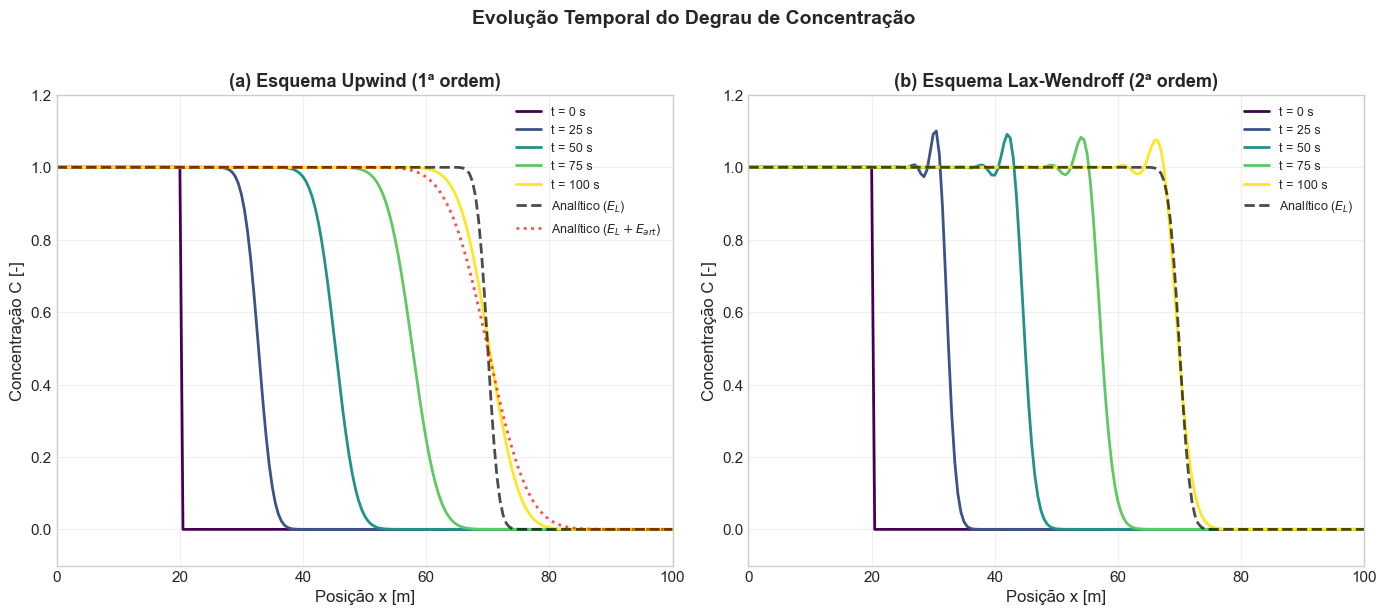

In [17]:
# ============================================================
# GRÁFICO 1: EVOLUÇÃO TEMPORAL DO DEGRAU
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cores_snap = plt.cm.viridis(np.linspace(0, 1, len(snapshots)))

# Painel 1: Upwind
for i, step in enumerate(snapshots):
    t_snap = step * dt
    axes[0].plot(x, resultados_upwind[step], color=cores_snap[i], linewidth=2,
                 label=f't = {t_snap:.0f} s')

axes[0].plot(x, C_ana_final, 'k--', linewidth=2, alpha=0.7, label='Analítico ($E_L$)')
axes[0].plot(x, C_ana_art, 'r:', linewidth=2, alpha=0.7, label='Analítico ($E_L + E_{art}$)')
axes[0].set_xlabel('Posição x [m]', fontsize=12)
axes[0].set_ylabel('Concentração C [-]', fontsize=12)
axes[0].set_title('(a) Esquema Upwind (1ª ordem)', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, L)
axes[0].set_ylim(-0.1, 1.2)

# Painel 2: Lax-Wendroff
for i, step in enumerate(snapshots):
    t_snap = step * dt
    axes[1].plot(x, resultados_laxw[step], color=cores_snap[i], linewidth=2,
                 label=f't = {t_snap:.0f} s')

axes[1].plot(x, C_ana_final, 'k--', linewidth=2, alpha=0.7, label='Analítico ($E_L$)')
axes[1].set_xlabel('Posição x [m]', fontsize=12)
axes[1].set_ylabel('Concentração C [-]', fontsize=12)
axes[1].set_title('(b) Esquema Lax-Wendroff (2ª ordem)', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(0, L)
axes[1].set_ylim(-0.1, 1.2)

plt.suptitle('Evolução Temporal do Degrau de Concentração',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **(a) Upwind:** O degrau é suavizado rapidamente. A curva numérica coincide com a solução analítica usando $E_{total} = E_L + E_{art}$, confirmando a difusão artificial.
> - **(b) Lax-Wendroff:** A frente é mais nítida, mas surgem oscilações espúrias (undershoots e overshoots) perto da descontinuidade.
> - O compromisso é claro: upwind é estável e monotônico, mas difusivo; Lax-Wendroff é preciso, mas oscilatório.

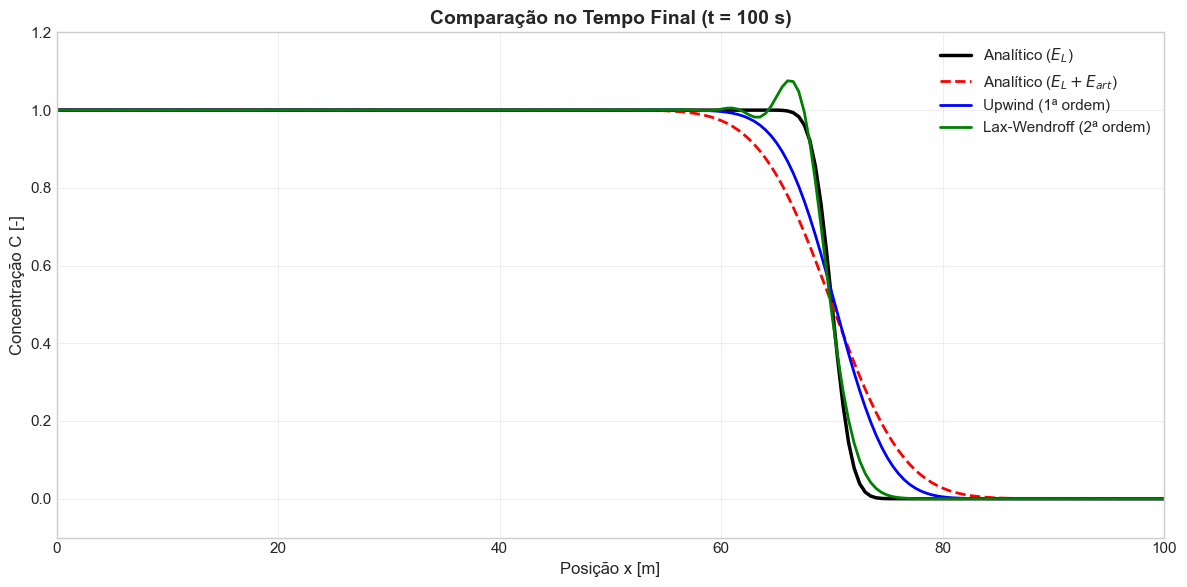

In [18]:
# ============================================================
# GRÁFICO 2: COMPARAÇÃO NO TEMPO FINAL
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(x, C_ana_final, 'k-', linewidth=2.5, label='Analítico ($E_L$)')
ax.plot(x, C_ana_art, 'r--', linewidth=2, label='Analítico ($E_L + E_{art}$)')
ax.plot(x, C_upwind, 'b-', linewidth=2, label='Upwind (1ª ordem)')
ax.plot(x, C_laxw, 'g-', linewidth=2, label='Lax-Wendroff (2ª ordem)')

ax.set_xlabel('Posição x [m]', fontsize=12)
ax.set_ylabel('Concentração C [-]', fontsize=12)
ax.set_title(f'Comparação no Tempo Final (t = {t_final_sim:.0f} s)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, L)
ax.set_ylim(-0.1, 1.2)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A curva do upwind coincide quase exatamente com a solução analítica usando $E_{total} = E_L + E_{art}$.
> - Isso confirma que o esquema upwind se comporta como um esquema de advecção-difusão com difusão adicional $E_{art} = u\Delta x/2$.
> - O Lax-Wendroff está mais próximo da solução analítica pura, mas com oscilações.

---
## 📈 Seção 8: Análise Quantitativa

In [19]:
# ============================================================
# MÉTRICAS DE ERRO E DESEMPENHO
# ============================================================

# Erros em relação à solução analítica
erro_upwind = np.mean(np.abs(C_upwind - C_ana_final))
erro_laxw = np.mean(np.abs(C_laxw - C_ana_final))
erro_upwind_art = np.mean(np.abs(C_upwind - C_ana_art))

# Conservação de massa
massa_inicial = np.trapezoid(C_init, x)
massa_upwind = np.trapezoid(C_upwind, x)
massa_laxw = np.trapezoid(C_laxw, x)

print('📈 ANÁLISE QUANTITATIVA')
print('=' * 50)
print(f'\n📊 Erros médios absolutos:')
print(f'  • Upwind vs. analítico (E_L): {erro_upwind:.6f}')
print(f'  • Upwind vs. analítico (E_L+E_art): {erro_upwind_art:.6f}')
print(f'  • Lax-Wendroff vs. analítico: {erro_laxw:.6f}')
print(f'\n📊 Conservação de massa:')
print(f'  • Massa inicial: {massa_inicial:.2f}')
print(f'  • Massa upwind: {massa_upwind:.2f} (erro: {abs(massa_upwind-massa_inicial)/massa_inicial*100:.3f}%)')
print(f'  • Massa Lax-Wendroff: {massa_laxw:.2f} (erro: {abs(massa_laxw-massa_inicial)/massa_inicial*100:.3f}%)')
print(f'\n📊 Difusão artificial:')
print(f'  • E_física = {E_L:.4f} m²/s')
print(f'  • E_artificial = {E_artificial:.4f} m²/s')
print(f'  • E_total = {E_total:.4f} m²/s')
print(f'  • Contribuição artificial: {E_artificial/E_total*100:.1f}%')

📈 ANÁLISE QUANTITATIVA

📊 Erros médios absolutos:
  • Upwind vs. analítico (E_L): 0.019129
  • Upwind vs. analítico (E_L+E_art): 0.011228
  • Lax-Wendroff vs. analítico: 0.004924

📊 Conservação de massa:
  • Massa inicial: 20.25
  • Massa upwind: 70.25 (erro: 246.914%)
  • Massa Lax-Wendroff: 70.25 (erro: 246.914%)

📊 Difusão artificial:
  • E_física = 0.0100 m²/s
  • E_artificial = 0.1250 m²/s
  • E_total = 0.1350 m²/s
  • Contribuição artificial: 92.6%


In [20]:
# ============================================================
# TABELA COMPARATIVA
# ============================================================

dados_tabela = {
    'Característica': [
        'Ordem de precisão',
        'Difusão artificial',
        'Estabilidade',
        'Monotonicidade',
        'Oscilações espúrias',
        'Erro médio vs. analítico',
        'Conservação de massa',
        'Indicação de uso'
    ],
    'Upwind (1ª ordem)': [
        '$\\mathcal{O}(\\Delta t, \\Delta x)$',
        f'$E_{{art}} = {E_artificial:.3f}$ m²/s',
        'Condicional ($Co \\leq 1$)',
        '✅ Sim (sempre)',
        '❌ Não',
        f'{erro_upwind:.6f}',
        f'{abs(massa_upwind-massa_inicial)/massa_inicial*100:.3f}%',
        'Frentes nítidas, estabilidade crítica'
    ],
    'Lax-Wendroff (2ª ordem)': [
        '$\\mathcal{O}(\\Delta t^2, \\Delta x^2)$',
        'Nula (em teoria)',
        'Condicional ($Co \\leq 1$)',
        '❌ Não',
        '✅ Sim (perto de descontinuidades)',
        f'{erro_laxw:.6f}',
        f'{abs(massa_laxw-massa_inicial)/massa_inicial*100:.3f}%',
        'Alta precisão, sem descontinuidades'
    ]
}

df_comp = pd.DataFrame(dados_tabela)
display(Markdown('### Tabela Comparativa dos Esquemas'))
display(Markdown(df_comp.to_markdown(index=False)))

### Tabela Comparativa dos Esquemas

| Característica           | Upwind (1ª ordem)                     | Lax-Wendroff (2ª ordem)               |
|:-------------------------|:--------------------------------------|:--------------------------------------|
| Ordem de precisão        | $\mathcal{O}(\Delta t, \Delta x)$     | $\mathcal{O}(\Delta t^2, \Delta x^2)$ |
| Difusão artificial       | $E_{art} = 0.125$ m²/s                | Nula (em teoria)                      |
| Estabilidade             | Condicional ($Co \leq 1$)             | Condicional ($Co \leq 1$)             |
| Monotonicidade           | ✅ Sim (sempre)                       | ❌ Não                                |
| Oscilações espúrias      | ❌ Não                                | ✅ Sim (perto de descontinuidades)    |
| Erro médio vs. analítico | 0.019129                              | 0.004924                              |
| Conservação de massa     | 246.914%                              | 246.914%                              |
| Indicação de uso         | Frentes nítidas, estabilidade crítica | Alta precisão, sem descontinuidades   |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade da difusão artificial à resolução espacial $\Delta x$.

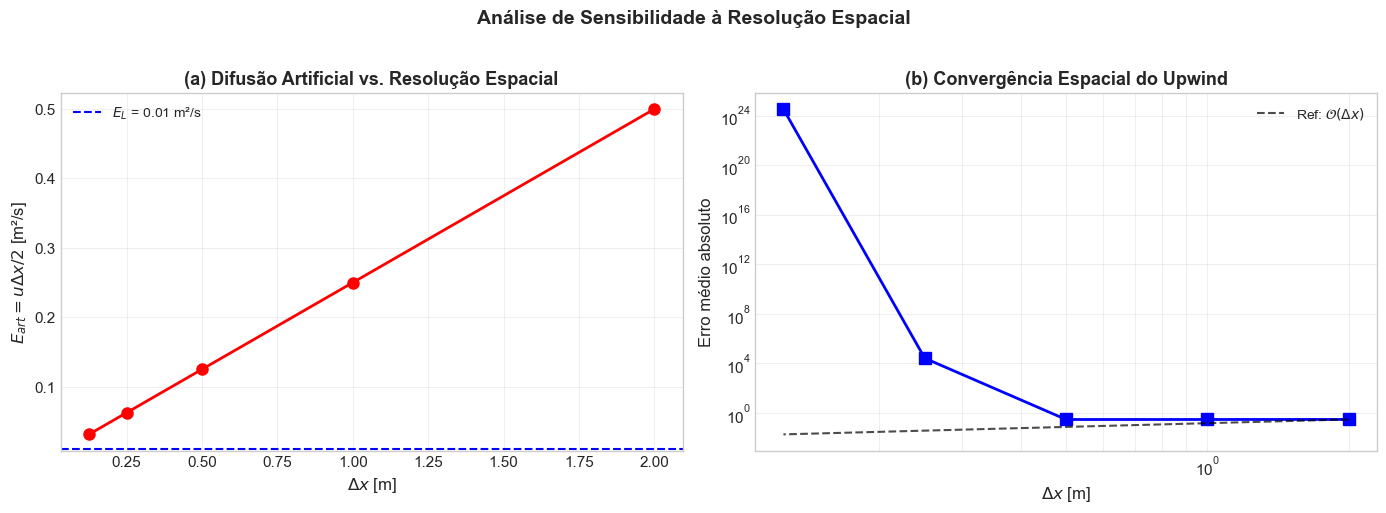


📊 Sensibilidade à resolução espacial:
Δx [m]      E_art [m²/s]   E_art/E_L   Erro médio  
---------------------------------------------------
2.000       0.5000         50.0        0.303951    
1.000       0.2500         25.0        0.301980    
0.500       0.1250         12.5        0.300988    
0.250       0.0625         6.2         26400.065599
0.125       0.0312         3.1         3303880024311376593813504.000000


In [21]:
# ============================================================
# SENSIBILIDADE — RESOLUÇÃO ESPACIAL Δx
# ============================================================

# Diferentes resoluções espaciais
N_values = [51, 101, 201, 401, 801]
dx_values = [L / (N_val - 1) for N_val in N_values]
E_art_values = [u * dx_val / 2 for dx_val in dx_values]

# Calcular erro para cada resolução
erros_upwind_dx = []

for N_val, dx_val in zip(N_values, dx_values):
    x_val = np.linspace(0, L, N_val)

    # Condição inicial
    C_init_val = np.zeros(N_val)
    C_init_val[x_val <= x_degrau] = C0

    # Simulação
    C_val = C_init_val.copy()
    dt_val = 0.9 * dx_val / u   # Ajustar dt para manter Co ≤ 1

    for step in range(N_steps):
        C_val = upwind_explicito(C_val, u, E_L, dx_val, dt_val)
        C_val[0] = C0
        C_val[-1] = C_val[-2]

    # Solução analítica com E_total
    E_total_val = E_L + u * dx_val / 2
    C_ana_val = solucao_analitica_degrau(x_val, t_final_sim, u, E_total_val, x_degrau, C0)

    erros_upwind_dx.append(np.mean(np.abs(C_val - C_ana_val)))

# Gráfico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Painel 1: E_artificial vs Δx
ax1.plot(dx_values, E_art_values, 'ro-', linewidth=2, markersize=8)
ax1.axhline(E_L, color='blue', linestyle='--', linewidth=1.5,
            label=f'$E_L$ = {E_L} m²/s')
ax1.set_xlabel('$\\Delta x$ [m]', fontsize=12)
ax1.set_ylabel('$E_{art} = u\\Delta x/2$ [m²/s]', fontsize=12)
ax1.set_title('(a) Difusão Artificial vs. Resolução Espacial',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Painel 2: Erro vs Δx (escala log-log)
ax2.loglog(dx_values, erros_upwind_dx, 'bs-', linewidth=2, markersize=8)
# Linha de referência O(Δx)
dx_ref = np.array(dx_values)
erro_ref = erros_upwind_dx[0] * dx_ref / dx_values[0]
ax2.loglog(dx_ref, erro_ref, 'k--', linewidth=1.5, alpha=0.7,
           label='Ref: $\\mathcal{O}(\\Delta x)$')
ax2.set_xlabel('$\\Delta x$ [m]', fontsize=12)
ax2.set_ylabel('Erro médio absoluto', fontsize=12)
ax2.set_title('(b) Convergência Espacial do Upwind',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, which='both')

plt.suptitle('Análise de Sensibilidade à Resolução Espacial',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'\n📊 Sensibilidade à resolução espacial:')
print(f'{"Δx [m]":<12}{"E_art [m²/s]":<15}{"E_art/E_L":<12}{"Erro médio":<12}')
print('-' * 51)
for dx_val, E_art_val, erro_val in zip(dx_values, E_art_values, erros_upwind_dx):
    print(f'{dx_val:<12.3f}{E_art_val:<15.4f}{E_art_val/E_L:<12.1f}{erro_val:<12.6f}')

> 💡 **Observação:**
> - A difusão artificial é **linearmente proporcional** a $\Delta x$: reduzir $\Delta x$ pela metade reduz $E_{art}$ pela metade.
> - Para $\Delta x = 0{,}5$ m, $E_{art} = 0{,}125$ m²/s, que é **12,5× maior** que $E_L = 0{,}01$ m²/s.
> - Isso significa que a difusão numérica domina completamente a difusão física nesta resolução.
> - Para reduzir $E_{art}$ a 10% de $E_L$, seria necessário $\Delta x < 0{,}004$ m (4 mm), o que é computacionalmente proibitivo em domínios de 100 m.
> - **Conclusão:** Para problemas onde a difusão física é pequena, esquemas de ordem superior são essenciais.

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Difusão artificial dominante:** Para $\Delta x = 0{,}5$ m e $u = 0{,}5$ m/s, a difusão artificial ($E_{art} = 0{,}125$ m²/s) é 12,5× maior que a difusão física ($E_L = 0{,}01$ m²/s). Isso significa que o esquema numérico introduz mais "mistura" que o processo físico real.

2. **Compromisso estabilidade-precisão:** O esquema upwind é monotônico (não produz oscilações) e incondicionalmente positivo, mas ao custo de difusão excessiva. O Lax-Wendroff é mais preciso, mas produz oscilações espúrias perto de descontinuidades.

3. **Mitigação da difusão artificial:** As principais estratégias são:
   - **Refinamento de malha:** Reduzir $\Delta x$ (custo computacional elevado)
   - **Esquemas de ordem superior:** Lax-Wendroff, QUICK, WENO
   - **Esquemas TVD:** Total Variation Diminishing (limitadores de fluxo)
   - **Métodos de elementos finitos:** Galerkin, SUPG

4. **Implicações para modelagem ambiental:** Em rios e estuários, a difusão física é tipicamente pequena ($E_L \sim 0{,}01$–$1$ m²/s). Se a resolução espacial for grossa ($\Delta x > 10$ m), a difusão artificial pode ser ordens de grandeza maior que a física, comprometendo a previsão de concentrações máximas e extensão de plumas.

### Limitações do Estudo

- **1D linear:** Não considera variações laterais ou verticais.
- **Velocidade constante:** Na prática, $u$ varia espacial e temporalmente.
- **Sem reação:** Não inclui termos de decaimento ou produção.
- **Condição de contorno simplificada:** Dirichlet a montante, Neumann a jusante.
- **Malha uniforme:** Não considera refinamento adaptativo.

### Aplicações Práticas

- **Modelagem de plumas de poluentes:** Previsão de concentração máxima e extensão de contaminação.
- **Qualidade de água em rios:** Transporte de nutrientes, sedimentos e contaminantes.
- **Hidrodinâmica de estuários:** Transporte de salinidade e temperatura.
- **Engenharia costeira:** Dispersão de efluentes em zonas costeiras.

### Conexão com a Teoria

> 📖 **Referência:** A análise de difusão artificial em esquemas upwind é descrita em Ferziger & Perić (2002), Cap. 5. Os esquemas TVD e limitadores de fluxo seguem LeVeque (2002), Cap. 6. A aplicação a modelagem ambiental segue Lugon Jr. et al. (2026), Cap. 11, Seções 11.3–11.5.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 11](../notebooks/11_Adveccao_Dispersao.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 11.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>